In [3]:
%pylab inline
import os
import pandas as pd
import numpy as np
import astropy.io.fits as pyfits
import astropy.table as astTable
import catutil as utilities
import smatch
dbDir='./wrkDir/database/s19-COSMOS/wcut/'
outDir=   './wrkDir/s19/s19-1/anaCat_newS19Mask_fdeltacut/plot/others/'
if False:
    aname='/home/xiangchong/work/gw_ipmu/work/COSMOS/cosmos_leauthaud_2007/COSMOS_ACS_catalog/acs_clean_only.fits'
else:
    aname='/work/xiangchong.li/work/COSMOS/cosmos_leauthaud_2007/COSMOS_ACS_catalog/acs_clean_only.fits'
    eliname='/work/xiangchong.li/work/galSim-HSC/s19/s19-1/anaCat_newS19Mask_fdeltacut/psfTest/fgcmStandardStars-06.fits'
    elinpname='/work/xiangchong.li/work/galSim-HSC/s19/s19-1/anaCat_newS19Mask_fdeltacut/psfTest/intermediate_products/all_fields_sm-S19A-g15_nonpsfstars.fits'
    psfname='/work/xiangchong.li/work/galSim-HSC/s19/s19-1/anaCat_newS19Mask_fdeltacut/psfTest/intermediate_products/all_fields_sm-S19A-g15_psfstars.fits'
    allname='/work/xiangchong.li/work/galSim-HSC/s19/s19-1/anaCat_newS19Mask_fdeltacut/psfTest/intermediate_products/all_fields_sm-S19A-g15_star.fits'

Populating the interactive namespace from numpy and matplotlib


In [4]:
coscat=pyfits.getdata(aname)
coscat=coscat[coscat['mu_class']<3]
ra=coscat['ALPHAPEAK_J2000']
dec=coscat['DELTAPEAK_J2000']

In [5]:
# read and match
catt=pyfits.getdata(allname)
cat=catt[catt['i_calib_psf_used']]
print(len(cat))
bmatch   =   smatch.match(cat['i_ra'],cat['i_dec'],1./3600.,ra,dec,maxmatch=1)
cmsk=np.zeros(len(ra),dtype=bool)
cat0=coscat[bmatch['i2']]
cat=cat[bmatch['i1']]
print(len(cat0),len(cat))

2260229
6427 6427


0.04356620507235102
[21.09 21.37 21.65 21.93 22.21] [0.02641409 0.02984729 0.03294455 0.03844052 0.0427825 ]


<ErrorbarContainer object of 3 artists>

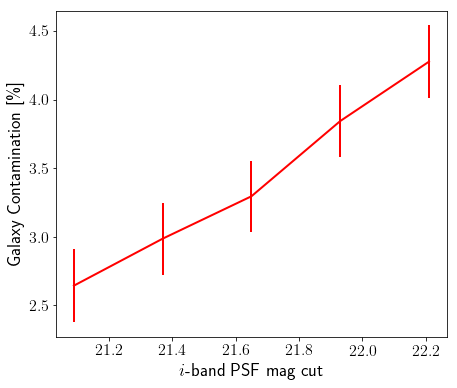

In [6]:
plt.close()
fig=plt.figure(figsize=(7,6))
ax=fig.add_subplot(1,1,1)
ax.set_xlabel(r'$i$-band PSF mag cut',fontsize=18)
ax.set_ylabel('Galaxy Contamination [\%]',fontsize=18)
cm=['red','blue','orange']
nb=6
bd0=np.linspace(21.,22.4,nb)

fmsk=(cat0['mu_class']==1)
mag=utilities.get_imag_psf(cat)
out=np.zeros(nb-1)
std=np.zeros(nb-1)
bd=bd0-0.05
for i in range(nb-1):
    msk=mag<bd[i+1]
    fmski=fmsk[msk]
    out[i]=np.sum(fmski)/np.sum(msk)
    std[i]=np.sqrt(np.sum(fmski))/np.sum(msk)
print(np.sum(fmsk)/len(cat0))
magave=(bd[1:]+bd[:-1])/2.
print(magave,out)
ax.errorbar(magave,out*100,std*100.,c=cm[0],label='PSF Star')

In [7]:
# read and match
catt=pyfits.getdata(allname)
cat=catt[~catt['i_calib_psf_used']]
print(len(cat))
bmatch   =   smatch.match(cat['i_ra'],cat['i_dec'],1./3600.,ra,dec,maxmatch=1)
cmsk=np.zeros(len(ra),dtype=bool)
cat0=coscat[bmatch['i2']]
cat=cat[bmatch['i1']]
print(len(cat0),len(cat))

186529
385 385


In [8]:
fmsk=(cat0['mu_class']==1)
mag=utilities.get_imag_psf(cat)
out=np.zeros(nb-1)
std=np.zeros(nb-1)
bd=bd0
for i in range(nb-1):
    msk=(mag<bd[i+1])
    fmski=fmsk[msk]
    out[i]=np.sum(fmski)/np.sum(msk)
    std[i]=np.sqrt(np.sum(fmski))/np.sum(msk)
print(np.sum(fmsk)/len(cat0))
magave=(bd[1:]+bd[:-1])/2.
print(magave,out)
ax.errorbar(magave,out*100,std*100.,c=cm[1],label='non-PSF Star')

0.06493506493506493
[21.14 21.42 21.7  21.98 22.26] [0.04117647 0.03381643 0.04453441 0.04983389 0.06460674]


<ErrorbarContainer object of 3 artists>

In [9]:
# read and match
cat=pyfits.getdata(elinpname)
print(len(cat))
bmatch   =   smatch.match(cat['i_ra'],cat['i_dec'],1./3600.,ra,dec,maxmatch=1)
cmsk=np.zeros(len(ra),dtype=bool)
cat0=coscat[bmatch['i2']]
cat=cat[bmatch['i1']]
print(len(cat0),len(cat))

87131
106 106


In [10]:
fmsk=(cat0['mu_class']==1)
mag=utilities.get_imag_psf(cat)
out=np.zeros(nb-1)
std=np.zeros(nb-1)
bd=bd0+0.05
for i in range(nb-1):
    msk=(mag<bd[i+1])
    fmski=fmsk[msk]
    out[i]=np.sum(fmski)/np.sum(msk)
    std[i]=np.sqrt(np.sum(fmski))/np.sum(msk)
print(np.sum(fmsk)/len(cat0))
magave=(bd[1:]+bd[:-1])/2.
print(magave,out)
ax.errorbar(magave,out*100,std*100.,c=cm[2],label='FGCM non-PSF Star')

0.04716981132075472
[21.19 21.47 21.75 22.03 22.31] [0.04166667 0.03389831 0.03125    0.025      0.04081633]


<ErrorbarContainer object of 3 artists>

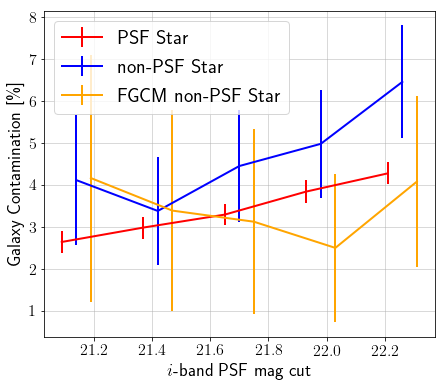

<Figure size 432x288 with 0 Axes>

In [11]:
ax.legend()
ax.grid()
plt.tight_layout()
fig

In [12]:
fig.savefig(os.path.join(outDir,'gal_contam_FGCMorNot.eps'))
fig.savefig(os.path.join(outDir,'gal_contam_FGCMorNot.png'))